# Task 2: Data Preprocessing and Pipeline Preparation

In this notebook, I prepare the images for model training. This includes handling duplicate images, dividing the labelled data into training and validation sets, resizing and normalising the images, and applying augmentation to the training set. I then create data loaders so the images can be supplied to the model efficiently.

In [1]:
from pathlib import Path
import random
import hashlib

import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_DIR = DATA_DIR / "train" / "train"
LABELS_PATH = DATA_DIR / "train_labels.csv"

labels = pd.read_csv(
    LABELS_PATH,
    dtype={"image_id": str}
)

print("Project root:", PROJECT_ROOT)
print("Labels shape:", labels.shape)
print("Training directory exists:", TRAIN_DIR.exists())
display(labels.head())

Project root: /Users/amanm/Documents/KAGGLE/ENGE707-Facial-Feature-Classification
Labels shape: (63660, 2)
Training directory exists: True


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


In [2]:
from collections import defaultdict
from tqdm.auto import tqdm

hash_groups = defaultdict(list)

for image_path in tqdm(sorted(TRAIN_DIR.glob("*.jpg")), desc="Checking duplicates"):
    with open(image_path, "rb") as file:
        image_hash = hashlib.sha256(file.read()).hexdigest()

    hash_groups[image_hash].append(image_path.stem)

duplicate_ids_to_remove = []

for image_ids in hash_groups.values():
    if len(image_ids) > 1:
        duplicate_ids_to_remove.extend(image_ids[1:])

clean_labels = labels[
    ~labels["image_id"].isin(duplicate_ids_to_remove)
].reset_index(drop=True)

print("Original images:", len(labels))
print("Duplicate images excluded:", len(duplicate_ids_to_remove))
print("Images remaining:", len(clean_labels))

Checking duplicates:   0%|          | 0/63660 [00:00<?, ?it/s]

Original images: 63660
Duplicate images excluded: 15
Images remaining: 63645


In [3]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    clean_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=clean_labels["class"]
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))

split_distribution = pd.DataFrame({
    "training": train_data["class"].value_counts().sort_index(),
    "validation": val_data["class"].value_counts().sort_index()
})

display(split_distribution)

Training images: 50916
Validation images: 12729


,training,validation
class,,
CatEye,11102,2775
CatFace,5553,1389
CatMouth,5553,1388
CatNose,5553,1388
DogEye,9261,2315
DogFace,4630,1158
DogMouth,4632,1158
DogNose,4632,1158


In [10]:
from torchvision import transforms

IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
    degrees=10,
    fill=(124, 116, 104)
),    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

validation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class_names = sorted(clean_labels["class"].unique())
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

print("Image size:", IMAGE_SIZE)
print("Class mapping:", class_to_index)

Image size: 224
Class mapping: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}


In [11]:
from PIL import Image
from torch.utils.data import Dataset

class FacialFeatureDataset(Dataset):
    def __init__(self, dataframe, image_directory, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_directory = image_directory
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = self.image_directory / f"{row['image_id']}.jpg"
        image = Image.open(image_path).convert("RGB")
        label = class_to_index[row["class"]]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = FacialFeatureDataset(
    train_data,
    TRAIN_DIR,
    transform=train_transform
)

validation_dataset = FacialFeatureDataset(
    val_data,
    TRAIN_DIR,
    transform=validation_transform
)

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(validation_dataset))

Training dataset size: 50916
Validation dataset size: 12729


In [12]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, labels_batch = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)

Training batches: 1592
Validation batches: 398
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


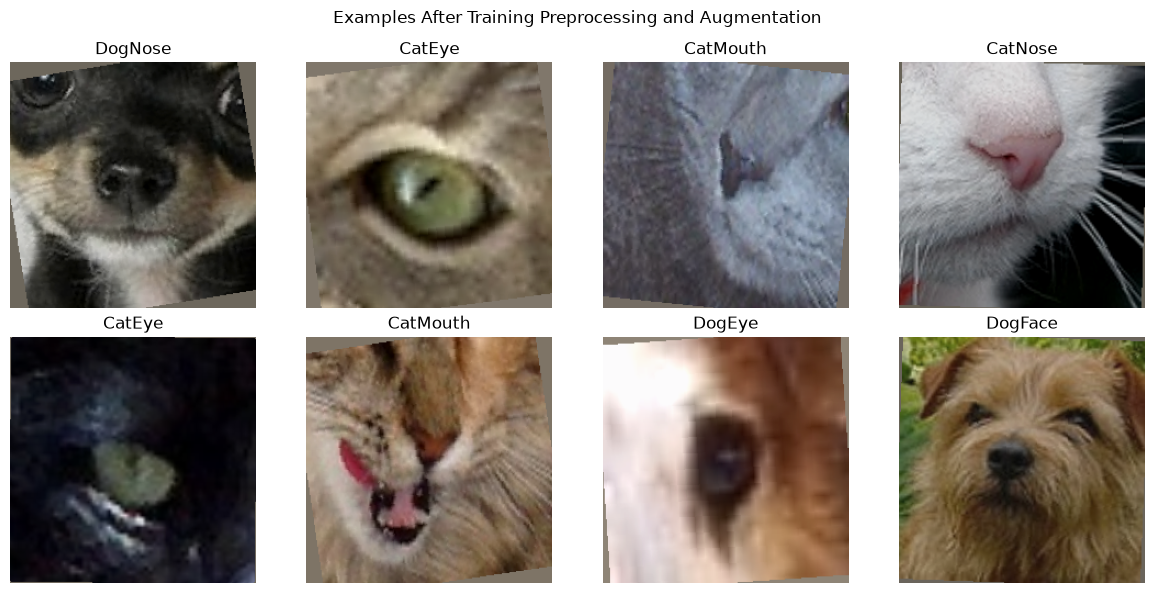

In [15]:
import matplotlib.pyplot as plt

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for index, ax in enumerate(axes.flatten()):
    image = images[index] * std + mean
    image = image.clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[labels_batch[index].item()])
    ax.axis("off")

plt.suptitle("Examples After Training Preprocessing and Augmentation")
plt.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_DIR / "augmented_samples.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Preprocessing Summary

Before preparing the data, I excluded 15 exact duplicate images while keeping the original files unchanged. The remaining 63,645 images were divided into an 80% training set and a 20% validation set using a stratified split, so each class kept a similar proportion in both sets.

All images are resized to 224 × 224 pixels and normalised using the standard ImageNet values required by the pretrained model. The training images also receive small random changes in orientation, rotation, brightness, contrast, and colour. These changes help the model handle natural differences between images and reduce overfitting. Validation images are only resized and normalised so that evaluation remains consistent.

Separate training and validation datasets and data loaders were created. This keeps validation images out of model training and helps prevent data leakage.